In [140]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import differential_evolution, minimize
from scipy.spatial import ConvexHull, QhullError

plt.style.use(style="seaborn-v0_8-whitegrid")
np.set_printoptions(precision=4, suppress=True)

In [141]:
from __future__ import annotations
from numpy.typing import NDArray

In [142]:
def jones_ar_coefficients(p: int, rng: np.random.Generator | int | None = None, *, return_pacf: bool = False):
    if not isinstance(p, (int, np.integer)) or p < 1:
        raise ValueError(f"p must be a positive integer, got {p}")
    generator = np.random.default_rng(rng)
    k = np.arange(1, p + 1)
    a = (k + 1) // 2
    b = k // 2 + 1
    beta_draws = generator.beta(a, b)
    pacf = 2.0 * beta_draws - 1.0
    phi = np.array([pacf[0]], dtype=float)
    for order in range(2, p + 1):
        reflection_coeff = pacf[order - 1]
        previous_phi = phi
        phi = np.empty(order, dtype=float)
        phi[:-1] = (previous_phi - reflection_coeff * previous_phi[::-1])
        phi[-1] = reflection_coeff
    if return_pacf:
        return phi, pacf
    return phi

def simulate_uniform_ar(phi, sample_size: int, burnin: int=500, half_width=1.0, rng=None):
    phi = np.asarray(phi, dtype=float)
    if phi.ndim != 1 or len(phi) == 0:
        raise ValueError("phi must be a nonempty one-dimensional coefficient vector")
    if not isinstance(sample_size, (int, np.integer)) or sample_size < 1:
        raise ValueError("sample_size must be a positive integer")
    if not isinstance(burnin, (int, np.integer)) or burnin < 0:
        raise ValueError("burnin must be a non-negative integer")
    if half_width <= 0:
        raise ValueError("half_width must be a positive number")
    generator = np.random.default_rng(rng)
    order = len(phi)
    total_length = burnin + order + sample_size
    innovations = generator.uniform(-half_width, half_width, size=total_length)
    series = np.zeros(total_length, dtype=float)
    for t in range(order, total_length):
        recent_values = series[t - np.arange(1, order + 1)]
        series[t] = phi @ recent_values + innovations[t]
    return series[burnin + order:]

phi: [-0.5571]


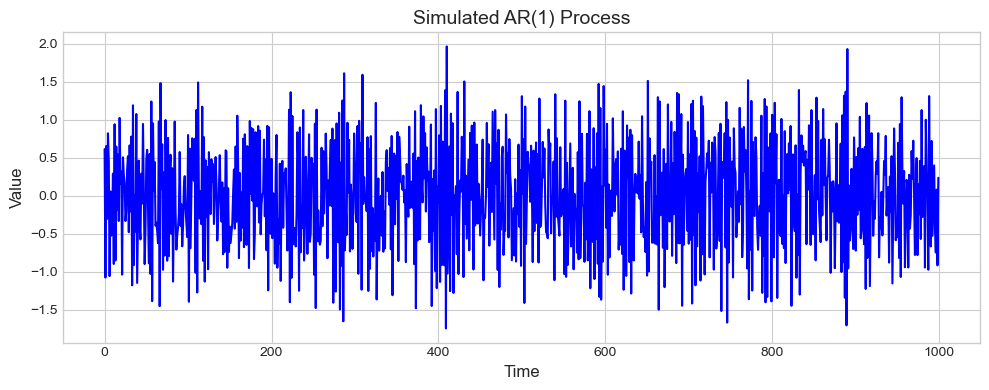

In [143]:
p = 1
coefficient_seed = 42
process_seed = 20260806
sample_size = 1000
burnin = 500
innovations_half_width = 1.0

phi = jones_ar_coefficients(p, rng=coefficient_seed, return_pacf=False)
ar_series = simulate_uniform_ar(phi, sample_size, burnin, innovations_half_width, rng=process_seed)

print("phi:", phi)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ar_series, color="blue", linewidth=1.5)
ax.set_title(f"Simulated AR({p}) Process", fontsize=14)
ax.set_xlabel("Time", fontsize=12)
ax.set_ylabel("Value", fontsize=12)
plt.tight_layout()
plt.show()

In [144]:
def ar_impulse_response(phi, maximum_lag):
    phi = np.asarray(phi, dtype=float)
    order = len(phi)
    psi = np.zeros(maximum_lag + 1)
    psi[0] = 1.0
    for lag in range(1, maximum_lag + 1):
        psi[lag] = sum(phi[j - 1] * psi[lag - j] for j in range(1, min(order, lag) + 1))
    return psi

In [145]:
def sliding_window_point_cloud(series, embedding_dimension: int):
    series = np.asarray(series, dtype=float)
    k = int(embedding_dimension)
    if series.ndim != 1:
        raise ValueError("series must be a one-dimensional array")
    if k < 1 or len(series) < k:
        raise ValueError("embedding_dimension must be a positive integer less than or equal to the length of the series")
    return np.column_stack([series[k - 1 - lag:len(series) - lag] for lag in range(k)])

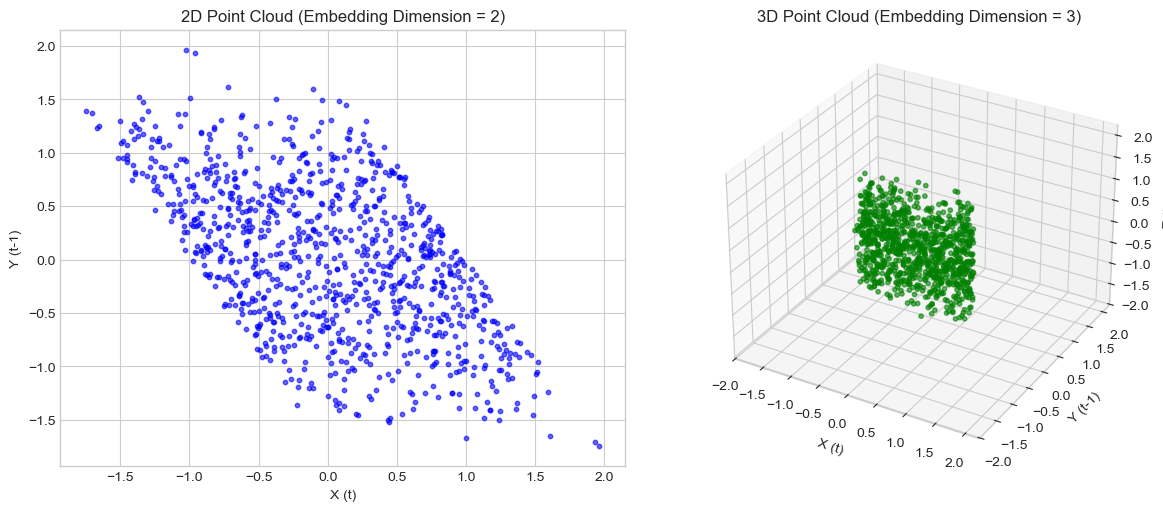

In [146]:
cloud_2d = sliding_window_point_cloud(ar_series, embedding_dimension=2)
cloud_3d = sliding_window_point_cloud(ar_series, embedding_dimension=3)

fig = plt.figure(figsize=(12, 5), constrained_layout=True)
ax_2d = fig.add_subplot(1, 2, 1)
ax_3d = fig.add_subplot(1, 2, 2, projection='3d')
ax_2d.scatter(cloud_2d[:, 0], cloud_2d[:, 1], color='blue', s=10, alpha=0.6)
ax_2d.set_title("2D Point Cloud (Embedding Dimension = 2)", fontsize=12)
ax_2d.set_xlabel("X (t)", fontsize=10)
ax_2d.set_ylabel("Y (t-1)", fontsize=10)
ax_3d.scatter(cloud_3d[:, 0], cloud_3d[:, 1], cloud_3d[:, 2], color='green', s=10, alpha=0.6)
ax_3d.set_title("3D Point Cloud (Embedding Dimension = 3)", fontsize=12)
ax_3d.set_xlabel("X (t)", fontsize=10)
ax_3d.set_ylabel("Y (t-1)", fontsize=10)
ax_3d.set_zlabel("Z (t-2)", fontsize=10)
plt.show()

In [147]:
def projected_subgradient_empirical_width(
    points,
    iterations=2_000,
    initial_step=0.2,
    patience=200,
    improvement_tolerance=1e-10,
    rng=None,
    initial_direction=None,
):
    """Minimize empirical directional width over the unit sphere."""
    points = np.asarray(points, dtype=float)
    if points.ndim != 2 or len(points) < 2:
        raise ValueError("points must have shape (n, k) with n >= 2.")
    if iterations < 1:
        raise ValueError("iterations must be positive.")
    if initial_step <= 0:
        raise ValueError("initial_step must be positive.")
    if not isinstance(patience, (int, np.integer)) or patience < 1:
        raise ValueError("patience must be a positive integer.")
    if improvement_tolerance < 0:
        raise ValueError("improvement_tolerance must be nonnegative.")

    generator = np.random.default_rng(rng)
    dimension = points.shape[1]

    if initial_direction is None:
        direction = generator.normal(size=dimension)
    else:
        direction = np.asarray(initial_direction, dtype=float)
        if direction.shape != (dimension,):
            raise ValueError(f"initial_direction must have shape ({dimension},).")

    direction_norm = np.linalg.norm(direction)
    if direction_norm <= np.finfo(float).eps:
        raise ValueError("initial_direction must be nonzero.")
    direction = direction / direction_norm

    width_history = np.empty(iterations)
    best_width_history = np.empty(iterations)
    best_width = np.inf
    best_direction = direction.copy()
    iterations_without_improvement = 0

    for iteration in range(iterations):
        projections = points @ direction
        maximum_index = int(np.argmax(projections))
        minimum_index = int(np.argmin(projections))
        width = projections[maximum_index] - projections[minimum_index]

        if width < best_width - improvement_tolerance:
            best_width = float(width)
            best_direction = direction.copy()
            iterations_without_improvement = 0
        else:
            iterations_without_improvement += 1

        width_history[iteration] = width
        best_width_history[iteration] = best_width

        if iterations_without_improvement >= patience:
            width_history = width_history[:iteration + 1]
            best_width_history = best_width_history[:iteration + 1]
            break

        # x_max-x_min is a subgradient of max_i <x_i,u>-min_i <x_i,u>.
        subgradient = points[maximum_index] - points[minimum_index]
        subgradient_norm = np.linalg.norm(subgradient)
        if subgradient_norm <= np.finfo(float).eps:
            width_history = width_history[:iteration + 1]
            best_width_history = best_width_history[:iteration + 1]
            break

        # Use a decreasing step and project the update back onto the unit sphere.
        step = initial_step / np.sqrt(iteration + 1.0)
        candidate = direction - step * subgradient / subgradient_norm
        candidate_norm = np.linalg.norm(candidate)
        if candidate_norm <= np.finfo(float).eps:
            candidate = generator.normal(size=dimension)
            candidate_norm = np.linalg.norm(candidate)
        direction = candidate / candidate_norm

    return {
        "minimum_width": best_width,
        "direction": best_direction,
        "width_history": width_history,
        "best_width_history": best_width_history,
    }


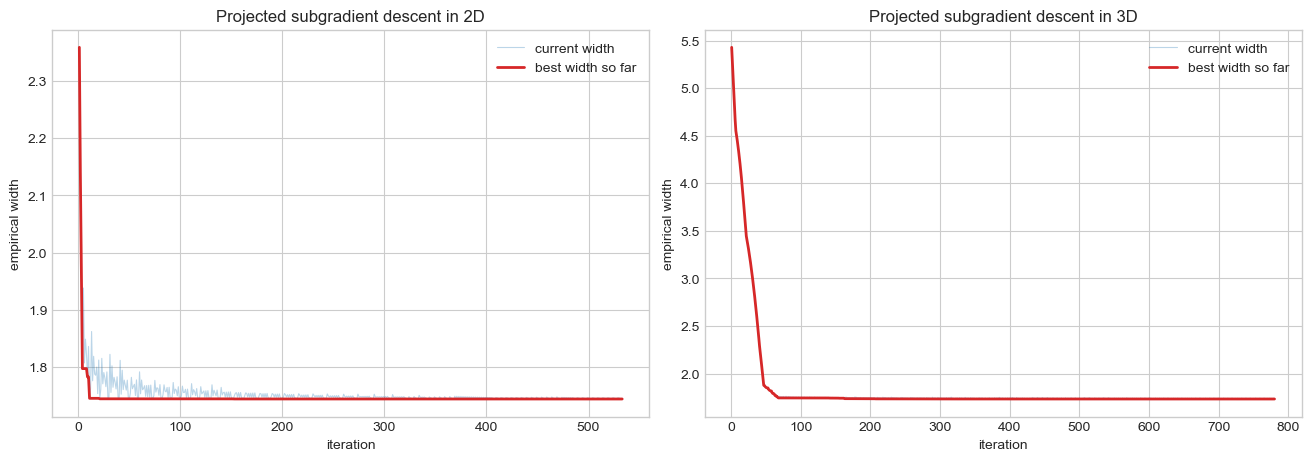

2D minimum width: 1.744386197927398
2D minimizing direction: [0.8709 0.4915]
3D minimum width: 1.7324025384039963
3D minimizing direction: [0.868  0.4963 0.0141]


In [148]:
subgradient_2d = projected_subgradient_empirical_width(
    cloud_2d,
    iterations=2_000,
    initial_step=0.2,
    rng=20260806,
)
subgradient_3d = projected_subgradient_empirical_width(
    cloud_3d,
    iterations=2_000,
    initial_step=0.2,
    rng=20260807,
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)

for axis, result, dimension in zip(
    axes,
    (subgradient_2d, subgradient_3d),
    (2, 3),
):
    iteration_numbers = np.arange(1, len(result["width_history"]) + 1)
    axis.plot(
        iteration_numbers,
        result["width_history"],
        color="tab:blue",
        alpha=0.3,
        linewidth=0.8,
        label="current width",
    )
    axis.plot(
        iteration_numbers,
        result["best_width_history"],
        color="tab:red",
        linewidth=2.0,
        label="best width so far",
    )
    axis.set(
        title=f"Projected subgradient descent in {dimension}D",
        xlabel="iteration",
        ylabel="empirical width",
    )
    axis.legend()

plt.show()

print("2D minimum width:", subgradient_2d["minimum_width"])
print("2D minimizing direction:", subgradient_2d["direction"])
print("3D minimum width:", subgradient_3d["minimum_width"])
print("3D minimizing direction:", subgradient_3d["direction"])


In [149]:
def first_plateau_selector(
    k_values,
    minimized_widths,
    relative_tolerance=0.10,
):
    """Return the first scale within a relative tolerance of the observed minimum."""
    k_values = np.asarray(k_values)
    minimized_widths = np.asarray(minimized_widths, dtype=float)

    if k_values.ndim != 1 or minimized_widths.ndim != 1:
        raise ValueError("k_values and minimized_widths must be one-dimensional.")
    if len(k_values) != len(minimized_widths):
        raise ValueError("k_values and minimized_widths must have equal lengths.")
    if len(k_values) == 0:
        raise ValueError("At least one scale is required.")
    if not np.all(np.isfinite(minimized_widths)):
        raise ValueError("All minimized widths must be finite.")
    if relative_tolerance < 0:
        raise ValueError("relative_tolerance must be nonnegative.")

    minimum_width = np.min(minimized_widths)
    plateau_threshold = minimum_width * (1.0 + relative_tolerance)
    first_plateau_index = np.flatnonzero(
        minimized_widths <= plateau_threshold
    )[0]

    return {
        "selected_k": int(k_values[first_plateau_index]),
        "minimum_width": float(minimum_width),
        "plateau_threshold": float(plateau_threshold),
        "relative_tolerance": float(relative_tolerance),
    }


plateau_relative_tolerance = 0.10


In [ ]:
experiment_orders = (1, 2, 3)
experiment_k_max = 10
experiment_sample_size = 2_000
experiment_burnin = 1_000
experiment_half_width = 1.0
experiment_iterations = 2_000
experiment_initial_step = 0.2
experiment_restarts = 8
experiment_seed = 20260808

experiment_rows = []

for order in experiment_orders:
    phi_order = jones_ar_coefficients(
        p=order,
        rng=experiment_seed + order,
    )
    series_order = simulate_uniform_ar(
        phi_order,
        sample_size=experiment_sample_size,
        burnin=experiment_burnin,
        half_width=experiment_half_width,
        rng=experiment_seed + 100 + order,
    )

    for k in range(1, experiment_k_max + 1):
        cloud_k = sliding_window_point_cloud(series_order, embedding_dimension=k)
        restart_fits = [
            projected_subgradient_empirical_width(
                cloud_k,
                iterations=experiment_iterations,
                initial_step=experiment_initial_step,
                rng=experiment_seed + 10_000 * order + 100 * k + restart,
            )
            for restart in range(experiment_restarts)
        ]
        width_fit = min(restart_fits, key=lambda fit: fit["minimum_width"])
        experiment_rows.append({
            "p": order,
            "k": k,
            "minimum_width": width_fit["minimum_width"],
            "phi": phi_order.copy(),
        })

minimum_width_experiment = pd.DataFrame(experiment_rows)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), constrained_layout=True, sharey=True)

for axis, order in zip(axes, experiment_orders):
    order_results = minimum_width_experiment[
        minimum_width_experiment["p"] == order
    ]
    axis.plot(
        order_results["k"],
        order_results["minimum_width"],
        marker="o",
        linewidth=2.0,
        color="tab:blue",
    )

    plateau_fit = first_plateau_selector(
        order_results["k"].to_numpy(),
        order_results["minimum_width"].to_numpy(),
        relative_tolerance=plateau_relative_tolerance,
    )
    plateau_choice = plateau_fit["selected_k"]
    axis.axvline(
        plateau_choice,
        color="tab:purple",
        linestyle=":",
        linewidth=2.0,
        label=fr"first 10% plateau choice $k={plateau_choice}$",
    )

    phi_order = order_results["phi"].iloc[0]
    recurrence_vector = np.r_[1.0, -phi_order]
    theoretical_minimum_width = (
        2.0 * experiment_half_width / np.linalg.norm(recurrence_vector)
    )
    axis.axhline(
        theoretical_minimum_width,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label=fr"theoretical minimum $={theoretical_minimum_width:.3f}$",
    )
    axis.axvline(
        order + 1,
        color="tab:red",
        linestyle="--",
        linewidth=1.5,
        label=fr"$p+1={order + 1}$",
    )
    axis.set(
        title=fr"AR({order})",
        xlabel=r"embedding dimension $k$",
        xticks=np.arange(1, experiment_k_max + 1),
    )
    axis.legend()

axes[0].set_ylabel(r"minimized empirical width $\hat{w}_k$")
plt.show()

print(minimum_width_experiment[["p", "k", "minimum_width"]].round(5).to_string(index=False))


In [ ]:
experiment_orders_456 = (4, 5, 6)
experiment_k_max_456 = 10
experiment_seed_456 = 20260809
experiment_rows_456 = []

for order in experiment_orders_456:
    phi_order = jones_ar_coefficients(
        p=order,
        rng=experiment_seed_456 + order,
    )
    series_order = simulate_uniform_ar(
        phi_order,
        sample_size=experiment_sample_size,
        burnin=experiment_burnin,
        half_width=experiment_half_width,
        rng=experiment_seed_456 + 100 + order,
    )

    for k in range(1, experiment_k_max_456 + 1):
        cloud_k = sliding_window_point_cloud(series_order, embedding_dimension=k)
        restart_fits = [
            projected_subgradient_empirical_width(
                cloud_k,
                iterations=experiment_iterations,
                initial_step=experiment_initial_step,
                rng=experiment_seed_456 + 10_000 * order + 100 * k + restart,
            )
            for restart in range(experiment_restarts)
        ]
        width_fit = min(restart_fits, key=lambda fit: fit["minimum_width"])
        experiment_rows_456.append({
            "p": order,
            "k": k,
            "minimum_width": width_fit["minimum_width"],
            "phi": phi_order.copy(),
        })

minimum_width_experiment_456 = pd.DataFrame(experiment_rows_456)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), constrained_layout=True, sharey=True)

for axis, order in zip(axes, experiment_orders_456):
    order_results = minimum_width_experiment_456[
        minimum_width_experiment_456["p"] == order
    ]
    axis.plot(
        order_results["k"],
        order_results["minimum_width"],
        marker="o",
        linewidth=2.0,
        color="tab:blue",
    )

    plateau_fit = first_plateau_selector(
        order_results["k"].to_numpy(),
        order_results["minimum_width"].to_numpy(),
        relative_tolerance=plateau_relative_tolerance,
    )
    plateau_choice = plateau_fit["selected_k"]
    axis.axvline(
        plateau_choice,
        color="tab:purple",
        linestyle=":",
        linewidth=2.0,
        label=fr"first 10% plateau choice $k={plateau_choice}$",
    )

    phi_order = order_results["phi"].iloc[0]
    recurrence_vector = np.r_[1.0, -phi_order]
    theoretical_minimum_width = (
        2.0 * experiment_half_width / np.linalg.norm(recurrence_vector)
    )
    axis.axhline(
        theoretical_minimum_width,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label=fr"theoretical minimum $={theoretical_minimum_width:.3f}$",
    )
    axis.axvline(
        order + 1,
        color="tab:red",
        linestyle="--",
        linewidth=1.5,
        label=fr"$p+1={order + 1}$",
    )
    axis.set(
        title=fr"AR({order})",
        xlabel=r"embedding dimension $k$",
        xticks=np.arange(1, experiment_k_max_456 + 1),
    )
    axis.legend()

axes[0].set_ylabel(r"minimized empirical width $\hat{w}_k$")
plt.show()

print(minimum_width_experiment_456[["p", "k", "minimum_width"]].round(5).to_string(index=False))


In [150]:
def aic_bic_ar_order(series, maximum_order):
    """Select conditional least-squares AR orders by Gaussian AIC and BIC."""
    series = np.asarray(series, dtype=float)
    maximum_order = int(maximum_order)
    if series.ndim != 1 or len(series) <= maximum_order + 1:
        raise ValueError("series is too short for the requested maximum_order.")

    # Use the same response times for every candidate so the criteria are comparable.
    response = series[maximum_order:]
    lag_matrix = np.column_stack([
        series[maximum_order - lag:len(series) - lag]
        for lag in range(1, maximum_order + 1)
    ])
    observation_count = len(response)
    criterion_rows = []

    for order in range(maximum_order + 1):
        if order == 0:
            design = np.ones((observation_count, 1))
        else:
            design = np.column_stack([
                np.ones(observation_count),
                lag_matrix[:, :order],
            ])

        coefficients, *_ = np.linalg.lstsq(design, response, rcond=None)
        residuals = response - design @ coefficients
        residual_sum_of_squares = max(
            float(residuals @ residuals),
            np.finfo(float).tiny,
        )
        parameter_count = order + 2  # intercept, AR coefficients, innovation variance
        gaussian_deviance = observation_count * np.log(
            residual_sum_of_squares / observation_count
        )
        criterion_rows.append({
            "order": order,
            "AIC": gaussian_deviance + 2.0 * parameter_count,
            "BIC": gaussian_deviance + np.log(observation_count) * parameter_count,
        })

    criterion_table = pd.DataFrame(criterion_rows)
    aic_order = int(criterion_table.loc[criterion_table["AIC"].idxmin(), "order"])
    bic_order = int(criterion_table.loc[criterion_table["BIC"].idxmin(), "order"])
    return aic_order, bic_order, criterion_table


def yule_walker_pacf(series, maximum_lag):
    """Estimate PACF values with the Durbin-Levinson/Yule-Walker recursion."""
    series = np.asarray(series, dtype=float)
    centered = series - np.mean(series)
    sample_size = len(centered)
    if maximum_lag < 1 or maximum_lag >= sample_size:
        raise ValueError("Require 1 <= maximum_lag < len(series).")

    autocovariance = np.array([
        centered[lag:] @ centered[:sample_size - lag] / sample_size
        for lag in range(maximum_lag + 1)
    ])
    if autocovariance[0] <= np.finfo(float).eps:
        raise ValueError("Cannot estimate PACF from a constant series.")

    pacf_values = np.empty(maximum_lag + 1)
    pacf_values[0] = 1.0
    previous_phi = np.empty(0)

    for order in range(1, maximum_lag + 1):
        if order == 1:
            reflection = autocovariance[1] / autocovariance[0]
        else:
            numerator = autocovariance[order] - (
                previous_phi @ autocovariance[order - 1:0:-1]
            )
            denominator = autocovariance[0] - (
                previous_phi @ autocovariance[1:order]
            )
            reflection = numerator / max(denominator, np.finfo(float).eps)

        pacf_values[order] = reflection
        updated_phi = np.empty(order)
        if order > 1:
            updated_phi[:-1] = previous_phi - reflection * previous_phi[::-1]
        updated_phi[-1] = reflection
        previous_phi = updated_phi

    return pacf_values


def pacf_cutoff_order(series, maximum_order, confidence_multiplier=1.96):
    """Choose the largest lag whose PACF exceeds the approximate confidence band."""
    pacf_values = yule_walker_pacf(series, maximum_order)
    cutoff = confidence_multiplier / np.sqrt(len(series))
    significant_lags = np.flatnonzero(np.abs(pacf_values[1:]) > cutoff) + 1
    selected_order = int(significant_lags[-1]) if len(significant_lags) else 0
    return selected_order, pacf_values, cutoff


def minimum_width_order(
    series,
    maximum_order,
    width_iterations,
    width_restarts,
    width_patience,
    initial_step,
    plateau_tolerance,
    rng,
):
    """Estimate p as one less than the first empirical width plateau scale."""
    minimized_widths = []
    for k in range(1, maximum_order + 2):
        cloud_k = sliding_window_point_cloud(series, embedding_dimension=k)
        restart_fits = [
            projected_subgradient_empirical_width(
                cloud_k,
                iterations=width_iterations,
                initial_step=initial_step,
                patience=width_patience,
                rng=rng,
            )
            for _ in range(width_restarts)
        ]
        best_fit = min(restart_fits, key=lambda fit: fit["minimum_width"])
        minimized_widths.append(best_fit["minimum_width"])

    k_values = np.arange(1, maximum_order + 2)
    plateau_fit = first_plateau_selector(
        k_values,
        minimized_widths,
        relative_tolerance=plateau_tolerance,
    )
    selected_order = plateau_fit["selected_k"] - 1
    return int(selected_order), np.asarray(minimized_widths)


def run_order_selection_comparison(
    orders=range(1, 7),
    replications=50,
    maximum_order=10,
    sample_size=2_000,
    burnin=1_000,
    innovation_half_width=1.0,
    width_iterations=2_000,
    width_restarts=1,
    width_patience=200,
    width_initial_step=0.2,
    plateau_tolerance=0.10,
    seed=20260810,
):
    """Compare minimum width, AIC, BIC, and PACF cutoff over simulated AR models."""
    generator = np.random.default_rng(seed)
    result_rows = []

    for true_order in orders:
        for replication in range(replications):
            # Each replication receives both a new stationary model and new innovations.
            phi = jones_ar_coefficients(true_order, rng=generator)
            series = simulate_uniform_ar(
                phi,
                sample_size=sample_size,
                burnin=burnin,
                half_width=innovation_half_width,
                rng=generator,
            )

            width_order, _ = minimum_width_order(
                series,
                maximum_order=maximum_order,
                width_iterations=width_iterations,
                width_restarts=width_restarts,
                width_patience=width_patience,
                initial_step=width_initial_step,
                plateau_tolerance=plateau_tolerance,
                rng=generator,
            )
            aic_order, bic_order, _ = aic_bic_ar_order(series, maximum_order)
            pacf_order, _, _ = pacf_cutoff_order(series, maximum_order)

            selections = {
                "Minimum width": width_order,
                "AIC": aic_order,
                "BIC": bic_order,
                "PACF cutoff": pacf_order,
            }
            for method, selected_order in selections.items():
                result_rows.append({
                    "true_order": true_order,
                    "replication": replication,
                    "method": method,
                    "selected_order": selected_order,
                    "correct": selected_order == true_order,
                })

        print(f"Completed p={true_order}: {replications} processes")

    return pd.DataFrame(result_rows)


Completed p=1: 50 processes
Completed p=2: 50 processes
Completed p=3: 50 processes
Completed p=4: 50 processes
Completed p=5: 50 processes
Completed p=6: 50 processes
Correct selections out of 50
method      AIC  BIC  Minimum width  PACF cutoff
true_order                                      
1            34   47             42           32
2            41   47             39           36
3            43   48             21           33
4            40   45             25           36
5            35   44             25           30
6            37   47             20           38

Accuracy
method       AIC   BIC  Minimum width  PACF cutoff
true_order                                        
1           0.68  0.94           0.84         0.64
2           0.82  0.94           0.78         0.72
3           0.86  0.96           0.42         0.66
4           0.80  0.90           0.50         0.72
5           0.70  0.88           0.50         0.60
6           0.74  0.94           0.40       

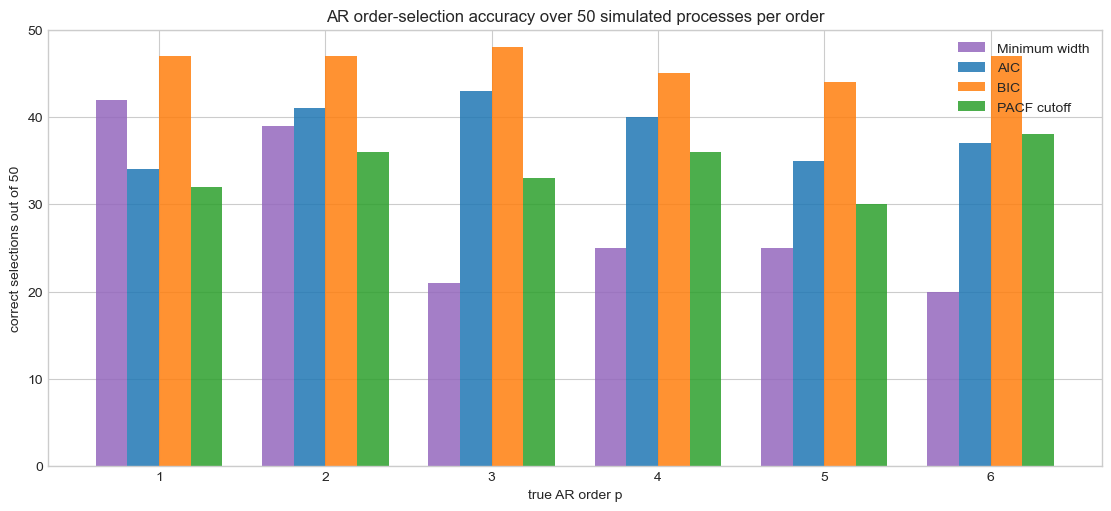

In [151]:
comparison_replications = 50
comparison_maximum_order = 10

order_comparison_results = run_order_selection_comparison(
    orders=range(1, 7),
    replications=comparison_replications,
    maximum_order=comparison_maximum_order,
    sample_size=2_000,
    burnin=1_000,
    innovation_half_width=1.0,
    width_iterations=2_000,
    width_restarts=1,
    width_patience=200,
    width_initial_step=0.2,
    plateau_tolerance=plateau_relative_tolerance,
    seed=20260810,
)

order_comparison_summary = (
    order_comparison_results
    .groupby(["true_order", "method"])["correct"]
    .agg(correct_count="sum", accuracy="mean")
    .reset_index()
)

correct_count_table = order_comparison_summary.pivot(
    index="true_order",
    columns="method",
    values="correct_count",
)
accuracy_table = order_comparison_summary.pivot(
    index="true_order",
    columns="method",
    values="accuracy",
)

print("Correct selections out of", comparison_replications)
print(correct_count_table.to_string())
print("\nAccuracy")
print(accuracy_table.round(3).to_string())

methods = ["Minimum width", "AIC", "BIC", "PACF cutoff"]
colors = ["tab:purple", "tab:blue", "tab:orange", "tab:green"]
true_orders = np.arange(1, 7)
bar_width = 0.19

fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
for method_index, (method, color) in enumerate(zip(methods, colors)):
    offset = (method_index - (len(methods) - 1) / 2) * bar_width
    counts = correct_count_table.loc[true_orders, method].to_numpy()
    ax.bar(
        true_orders + offset,
        counts,
        width=bar_width,
        label=method,
        color=color,
        alpha=0.85,
    )

ax.set(
    title="AR order-selection accuracy over 50 simulated processes per order",
    xlabel="true AR order p",
    ylabel="correct selections out of 50",
    xticks=true_orders,
    ylim=(0, comparison_replications),
)
ax.legend()
plt.show()
